In [1]:
import sys
import pandas as pd

import numpy as np
%load_ext autoreload
%autoreload 2

import mvEEG.mvEEG as mvEEG
import tqdm.auto as ta

from sklearn.covariance import LedoitWolf
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import LabelEncoder
from mne.parallel import parallel_func

import matplotlib.pyplot as plt
import seaborn as sns 
from os import path

from glob import glob

import mne_bids

In [2]:
OVERWRITE = False
RUN_DESCRIPTION = "signedDprime"  # description for saving outputs, either "signedDprime" or "signedCorrWhite"
DROP_SS0 = True  # where to drop A0 and M0
SEED = 2026  # random seed for reproducibility, reset per subject


if RUN_DESCRIPTION == "signedCorrWhite":
    # if correlation whitened, then we need to zscore the data before computing RDMs
    from scipy.stats import zscore

    CORRWHITE = True
elif RUN_DESCRIPTION == "signedDprime":
    CORRWHITE = False

In [3]:
def _mean_by_condition(X, conds):
    """
    computes the average of each condition in X, ordered by conds
    returns a n_conditions x n_channels array
    """
    avs = np.zeros((len(np.unique(conds)), *X.shape[1:]))
    for cond in sorted(np.unique(conds)):
        X_cond = X[conds == cond]
        avs[cond] = X_cond.mean(axis=0)
    return avs


def _means_and_prec(X, conds, CORRWHITE=CORRWHITE):
    """
    Returns condition averages and demeaned inverse covariance
    Covariance is regularized by ledoit-wolf procedure
    """
    cond_means = _mean_by_condition(X, conds)
    cond_means_for_each_trial = cond_means[conds]
    X_demean = X - cond_means_for_each_trial  # demean
    if CORRWHITE:
        # if correlation whitened, then we need to zscore the data before computing RDMs
        # the covariance matrix will then approximate the correlation matrix, and the precision matrix will be the inverse correlation matrix
        X_demean = zscore(X_demean, axis=0)

    return cond_means, LedoitWolf(assume_centered=True).fit(X_demean).precision_


def _calc_rdm_crossnobis_single(meas1, meas2, noise):
    """
    Calculates RDM using crossnobis distance using means from x and y, and covariance
    Largely taken from https://github.com/rsagroup/rsatoolbox/blob/main/src/rsatoolbox/rdm/calc.py#L429
    Updated to return the signed square root of the RDM because
    LDC is an estimator of the squared mahalonobis distance
    """
    kernel = meas1 @ noise @ meas2.T
    rdm = np.expand_dims(np.diag(kernel), 0) + np.expand_dims(np.diag(kernel), 1) - kernel - kernel.T
    return np.sign(rdm) * np.sqrt(np.abs(rdm))  # NOTE: we are converting to signed d' here


def _crossnobis_single(X_train, conds_train, X_test, conds_test):
    """
    Uses condition means from both train and test, but only uses the training
    examples to compute the noise covariance/precision matrix. You may have another
    preference, but I did it this way to avoid train-test leakage.
    """
    means_train, noise_train = _means_and_prec(X_train, conds_train)
    means_test = _mean_by_condition(X_test, conds_test)
    rdm = _calc_rdm_crossnobis_single(means_train, means_test, noise_train)
    return rdm


def _crossnobis_train_test_across_time(Xdata, y, train, test, cond_order):
    # assumes Xdata is n_trials x n_features x n_times

    X_train, y_train = Xdata[train], y[train]
    X_test, y_test = Xdata[test], y[test]

    # calculate RDMS over time for this fold
    rdms = [_crossnobis_single(X_train[..., t], y_train, X_test[..., t], y_test) for t in range(Xdata.shape[-1])]

    # concatenate over time and resort to the given cond_order
    return np.stack(rdms, axis=2)[np.ix_(cond_order, cond_order)]


def crossnobis(Xdata, ydata, cond_order, test_size=0.5, n_splits=1000, n_jobs=-1):
    """
    Wrapper for a parallel function to calculate a series of crossnobis distances
    n_splits and n_jobs should be given as arguments upon class initialization


    """

    enc = LabelEncoder()  # converts condition labels to integer codes
    conds = enc.fit_transform(ydata)
    cond_order = enc.transform(cond_order)  # how to resort the final RDMs

    cv = StratifiedShuffleSplit(n_splits=n_splits, test_size=test_size)

    parallel, p_func, _ = parallel_func(_crossnobis_train_test_across_time, n_jobs)
    rdms = parallel(
        p_func(Xdata=Xdata, y=conds, train=train_idx, test=test_idx, cond_order=cond_order)
        for train_idx, test_idx in cv.split(Xdata, conds)
    )

    rdms = np.stack(rdms, axis=0)
    return rdms.mean(0)  # average over folds

In [4]:
import json

with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['19', '32', '33']

In [5]:
code_dict = {
    "A0": 10,
    "A1": 11,
    "A2": 12,
    "A3": 13,
    "A4": 14,
    "A6": 16,
    "A8": 18,
    "M0": 20,
    "M1": 21,
    "M2": 22,
    "M3": 23,
    "M4": 24,
    "M6": 26,
    "M8": 28,
}
conditions = list(code_dict.keys())

if DROP_SS0:
    conditions.remove("A0")
    conditions.remove("M0")

ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan2"
dropped_chans = {"eeg": ["TP9", "Fp1", "Fp2"], "eog": "ALL", "eyegaze": "ALL", "pupil": "ALL", "misc": "ALL"}
# EOG and EYE channels will be analyzed separately, to see if they drive decoding results
# EOG_CHANS = ["HEOG", "VEOG"]
# EYE_CHANS = ["xpos_left", "xpos_right", "ypos_left", "ypos_right"]

SUB_IGNORE_CHANS = {}
bad_epochs = (
    {  # epochs which didn't align with eye tracking for one reason or another, and were excluded during preprocessing
        "05": [737, 739, 740, 741, 745, 746],
        "21": [649, 650, 651, 652],
    }
)
bad_blocks = {
    # blocks for which participants admitted they were confused about the task (normally at the start, or first switch to the other task)
    "17": [6],  # first attention block
    "22": [6, 7, 8, 9],  # was doing SS0 incorrectly for the first few WM blocks
    "32": [6],  # first WM block
}

# participant who came back for a second session. We are going to combine the two sessions.
split_sess_subs = {"22": "34"}

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans=dropped_chans,
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1200],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

delay_window = (wrangl.t > 300) & (
    wrangl.t < 1100
)  # time window to average distances over, only includes when probes could appear

In [6]:
def load_behavioral_data(wrangl, isub):
    # get all behavioral files for this subject
    basepath = "/".join(
        str(wrangl.bids_path.copy().update(subject=wrangl.subs[isub], datatype="beh").fpath).split("/")[:-1]
    )
    beh_files = glob(path.join(basepath, "*_data_block*.csv"))

    # load and concatenate behavioral data
    beh = pd.DataFrame()
    for f in beh_files:
        df_block = pd.read_csv(f)
        beh = pd.concat([beh, df_block], axis=0)

    # sort by Block and Trial to ensure proper alignment with EEG epochs
    beh = beh.sort_values(by=["Block", "Trial"]).reset_index(drop=True)

    beh = beh.loc[~(beh.REJ == 1)].reset_index(
        drop=True
    )  # remove real time eye tracking rejects, which aren't in the EEG
    beh = beh.drop(bad_epochs.get(wrangl.subs[isub], [])).reset_index(
        drop=True
    )  # drop bad epochs due to sync errors with eye tracking
    beh = beh.loc[~wrangl.artifacts[isub], :].reset_index(
        drop=True
    )  # drop epochs marked as artifacts during preprocessing

    if wrangl.subs[isub] == "13":
        beh["Subject"] = 13  # fix subject number for sub-13, which was mis-labeled as sub-12 in behavioral data

    return beh

  0%|          | 0/34 [00:00<?, ?it/s]

Skipping 01; already exists and not overwriting
Skipping 02; already exists and not overwriting
Skipping 03; already exists and not overwriting
Skipping 04; already exists and not overwriting
Skipping 05; already exists and not overwriting
Skipping 06; already exists and not overwriting
Skipping 07; already exists and not overwriting
Skipping 08; already exists and not overwriting
Skipping 09; already exists and not overwriting
Skipping 10; already exists and not overwriting
Skipping 11; already exists and not overwriting
Skipping 12; already exists and not overwriting
Skipping 13; already exists and not overwriting
Skipping 14; already exists and not overwriting
Skipping 15; already exists and not overwriting
Skipping 16; already exists and not overwriting
Subject 17 condition counts: M1    109
M8    108
M0    108
M6    107
M2    106
M4    102
M3    100
A0     98
A4     95
A8     94
A2     92
A3     92
A1     92
A6     86
Name: count, dtype: int64


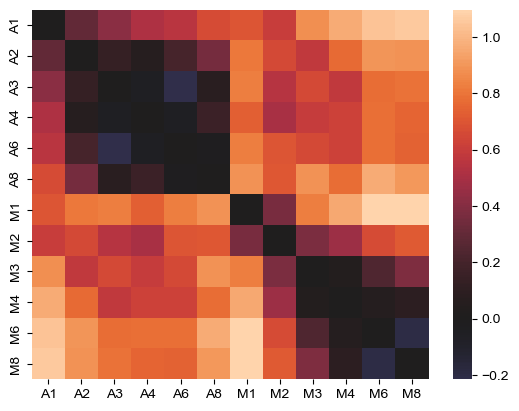

Skipping 18; already exists and not overwriting
Skipping 19 due to rejection in trial counts or behavioral analyses
Skipping 20; already exists and not overwriting
Skipping 21; already exists and not overwriting
concatenating 34 onto 22
Subject 22 condition counts: A0    215
A2    181
A3    173
A1    172
A4    171
A8    171
A6    164
M0    160
M2    144
M3    142
M1    137
M4    128
M6    126
M8    118
Name: count, dtype: int64


/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


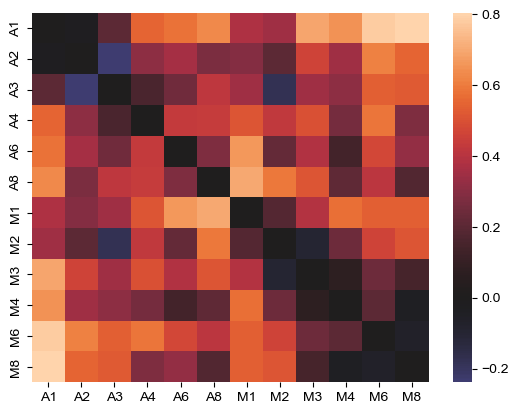

Skipping 23; already exists and not overwriting
Skipping 25; already exists and not overwriting
Skipping 26; already exists and not overwriting
Skipping 27; already exists and not overwriting
Skipping 28; already exists and not overwriting
Skipping 30; already exists and not overwriting
Skipping 31; already exists and not overwriting
Skipping 32 due to rejection in trial counts or behavioral analyses
Skipping 33 due to rejection in trial counts or behavioral analyses
Skipping 34, was concatenated onto another subject ID
Skipping 35; already exists and not overwriting
Skipping 36; already exists and not overwriting


In [7]:
for isub in ta.tqdm(range(wrangl.nsub)):
    if wrangl.subs[isub] in rejected_subs:
        print(f"Skipping {wrangl.subs[isub]} due to rejection in trial counts or behavioral analyses")
        continue

    sub_path = mne_bids.BIDSPath(
        root=ROOT,
        task=EXPERIMENT_NAME,
        subject=wrangl.subs[isub],
        datatype="RDMs",
        description=RUN_DESCRIPTION,
        extension=".npy",
        suffix="rdm",
        check=False,
    )
    sub_path.mkdir()
    if sub_path.fpath.exists() and not OVERWRITE:
        print(f"Skipping {wrangl.subs[isub]}; already exists and not overwriting")
        continue

    # Load the data
    Xdata, ydata = wrangl.load_eeg(isub, reject=True, drop_chans_manual=SUB_IGNORE_CHANS.get(wrangl.subs[isub], []))
    beh = load_behavioral_data(wrangl, isub)
    assert Xdata.shape[0] == beh.shape[0], "Mismatch between EEG epochs and behavioral data"

    if wrangl.subs[isub] in split_sess_subs.keys():
        second_sess_id = split_sess_subs[wrangl.subs[isub]]
        print(f"concatenating {second_sess_id} onto {wrangl.subs[isub]}")
        isub_2nd = np.where([s == second_sess_id for s in wrangl.subs])[0][0]
        Xdata_2nd, ydata_2nd = wrangl.load_eeg(
            isub_2nd, reject=True, drop_chans_manual=SUB_IGNORE_CHANS.get(wrangl.subs[isub], [])
        )
        beh_2nd = load_behavioral_data(wrangl, isub_2nd)
        assert Xdata_2nd.shape[0] == beh_2nd.shape[0], "Mismatch between EEG epochs and behavioral data"

        # concatenate the data
        beh_2nd.Block += beh.Block.max()  # update block numbers for second session to be continuous with first session
        Xdata = np.concatenate([Xdata, Xdata_2nd], axis=0)
        ydata = np.concatenate([ydata, ydata_2nd], axis=0)
        beh = pd.concat([beh, beh_2nd], axis=0).reset_index(drop=True)

    if wrangl.subs[isub] in split_sess_subs.values():
        print(f"Skipping {wrangl.subs[isub]}, was concatenated onto another subject ID")
        continue

    # keep only main task conditions, not trials with probes
    keep_cond_idx = ydata < 30
    Xdata = Xdata[keep_cond_idx]
    ydata = ydata[keep_cond_idx]
    beh = beh.loc[keep_cond_idx, :].reset_index(drop=True)

    if wrangl.subs[isub] in bad_blocks:
        keep_blocks = ~beh.Block.isin(bad_blocks[wrangl.subs[isub]])
        beh = beh[keep_blocks].reset_index(drop=True)
        Xdata = Xdata[keep_blocks, :, :]
        ydata = ydata[keep_blocks]

    # potentially drop SS0 conditions
    cond_idx = beh["trial_condition"].isin(conditions).index
    beh = beh.loc[cond_idx].reset_index(drop=True)
    Xdata = Xdata[cond_idx]
    ydata = ydata[cond_idx]

    trial_conds = beh["trial_condition"].values
    print(f"Subject {wrangl.subs[isub]} condition counts:", pd.Series(trial_conds).value_counts())

    np.random.seed(SEED)  # for reproducibility
    sub_rdms = crossnobis(Xdata, trial_conds, conditions, n_splits=2_500, n_jobs=-1)
    np.save(sub_path.copy(), sub_rdms)

    # plot delay-period RDM
    sub_rdm_delay = sub_rdms[..., delay_window].mean(-1)
    sns.heatmap(sub_rdm_delay, xticklabels=conditions, yticklabels=conditions, center=0)
    plt.show()
    plt.close()